In [1]:
import math
import matplotlib.pyplot as plt
import numpy as np
import matplotx
import tensorflow as tf
plt.style.use(matplotx.styles.github['light'])

/Users/az9umas/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


[-10.          -9.7979798   -9.5959596   -9.39393939  -9.19191919]
[-1000.          -940.61005937  -883.61937918  -828.97849014
  -776.63792295]
[299.970001   287.97183143 276.21853482 264.71011119 253.44656053]


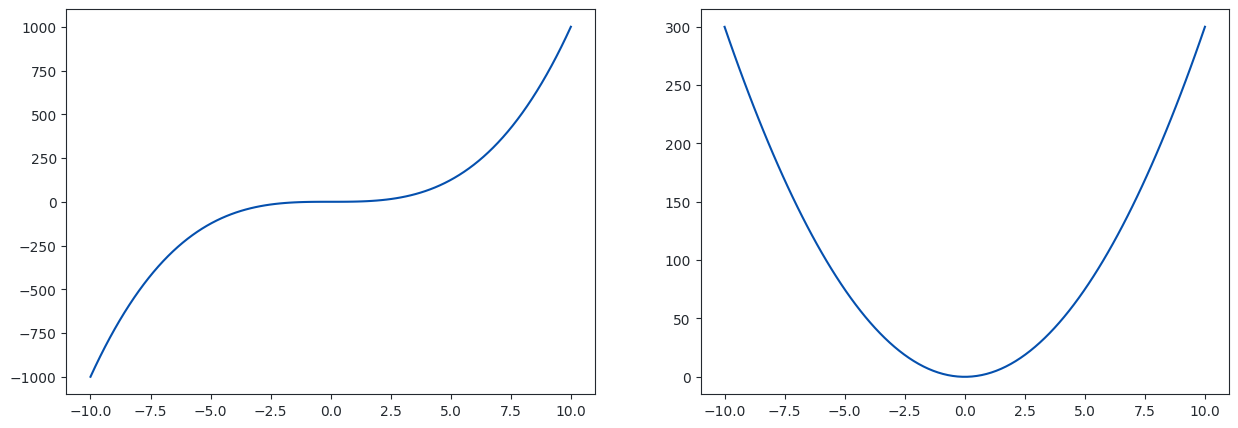

In [2]:
f = lambda x : x ** 3
ep = 0.001
df_dx = lambda x: (f(x + ep) - f(x)) / ep

x = np.linspace(-10, 10, 100)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize = (15, 5))

print(x[:5])
print(f(x[:5]))
print(df_dx(x[:5]))

ax1.plot(x, f(x))
ax2.plot(x, df_dx(x))

In [3]:
class test:

    def __init__(self, stuff):
        self.stuff = stuff

    def __enter__(self):
        print("enter: ", self.stuff)
        return "hello"
    
    def __exit__(self, type, value, traceback):
        print("exit:", type, value, traceback)
        return "hi"
    
with test(12) as lol:
    print(lol)

enter:  12
hello
exit: None None None


In [4]:
x = tf.Variable(3.0)

with tf.GradientTape() as tape:
    f = x * x
    df_dx = tape.gradient(f, [x])
    print(df_dx)

[<tf.Tensor: shape=(), dtype=float32, numpy=6.0>]


In [5]:
class Dual:
    def __init__(self, num, derv = 1):
        self.num = num
        self.derv = derv

    def sin(self):
        return Dual(math.sin(self.num), math.cos(self.num) * self.derv)
    
    def __add__(self, other):
        if isinstance(other, Dual):
            other = other.num
        return Dual(self.num + other, 1)
    
    def __mul__(self, other):
        return Dual(self.num * other.num, self.num * other.derv + self.derv * other.num)

    def __repr__(self):
        return f"{self.num}, {self.derv}"

In [6]:
x = Dual(0.1)
s = x.sin()
print(s * x)
print(math.sin(0.1) * 0.1, 0.1 * math.cos(0.1) + math.sin(0.1))


0.009983341664682815, 0.19933383317463074
0.009983341664682815 0.19933383317463074


$$v_1 = x$$
$$v_2 = \sin \left(v_1\right)$$
$$v_3 = \sin \left(v_2\right)$$
$$v_4 = v_3 \cdot v_1$$

Full Equation: $$x \cdot \sin \left( \sin \left( x \right) \right)$$

In [7]:
x = tf.Variable(0.5)
v1 = x
v2 = tf.sin(v1)
v3 = tf.sin(v2)
v4 = v3 * v1
print("Tensorflow:", v4)

x_ = Dual(0.5)
v1_ = x_
v2_ = v1_.sin()
v3_ = v2_.sin()
v4_ = v3_ * v1_
print("Dual test:", v4_)

Tensorflow: tf.Tensor(0.23063478, shape=(), dtype=float32)
Dual test: 0.23063477751659034, 0.8505915292190704



Tensorflow:
$$
\begin{align*}
v_2 &= \sin x \\
v_3 &= \sin \left( v_2 \right) \\
\frac{\partial v_3}{\partial v_2} &= \frac{\partial \sin \left( v_2 \right) }{\partial v_2}
= \frac{\partial \sin \left( \sin x \right) }{\partial \sin x}
= \cos \sin x
\end{align*}
$$

In [8]:
x = tf.Variable(0.5)
v1 = x
with tf.GradientTape() as tape:
    v2 = tf.sin(v1)
    v3 = tf.sin(v2)
    v4 = v3 * v1

print(tape.gradient(v3, v2))
print(math.cos(math.sin(0.5)))

tf.Tensor(0.88726, shape=(), dtype=float32)
0.8872600507176526


$$
v_4 = v_3 \cdot v_2 \\
\begin{align*}
\frac{\partial v_4}{\partial v_2} &= \frac{\partial \left( v_3 \cdot v_1 \right)}{\partial v_2}
= \frac{\partial \left(v_1 \cdot \sin v_2 \right)}{\partial v_2}
= v_1 \cos v_2
\end{align*}
\\
\text{On the other hand, }
\begin{align*}
\\
\frac{\partial \left(x \cdot \sin \left( \sin x \right) \right)}{\partial \sin x}
&= 1 
\end{align*}
$$